# 空间轨迹 SpaTrack 学习手册

In [ ]:
from datetime import date
print("Author: Biomamba_pudding")
print("Date:", date.today())

Author: Biomamba
Date: 2025-09-25


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 一、SpaTrack 空间分析

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/spatrack.png)

**SpaTrack** 是一个专门用于**空间转录组 ($\text{Spatial Transcriptomics, ST}$) 数据**的软件，其核心功能是进行**空间轨迹推断** ($\text{Spatial Trajectory Inference}$)，以重建细胞状态在组织中的演变路径。

## 1. 核心原理：最优传输 (Optimal Transport, OT)

SpaTrack 的最大创新在于它采用了**最优传输 ($\text{OT}$) 理论**来推断轨迹。它将细胞状态之间的转换成本计算为最小化成本问题：

* **转换成本**：计算细胞状态从一个 Spot 转移到另一个 Spot 所需的最小“成本”。
* **成本整合**：这个成本同时整合了两个关键因素：
    1.  **基因表达相似性**：转录组状态越相似，转换成本越低。
    2.  **空间距离**：物理距离越近，转换成本越低。

**结论**：通过这种方式，SpaTrack 推断出的细胞轨迹在**转录组相似性**和**空间连续性**上都是最优的，确保了轨迹的生物学合理性。

## 2. 主要功能与优势

| 功能 | 描述 | 生物学意义 |
| :--- | :--- | :--- |
| **高精度轨迹** | 在单个组织切片内，构建反映真实分化拓扑的精细局部轨迹 | 揭示组织内细胞状态的细致、局部的渐变模式 |
| **时空动态追踪** | 可整合多个时间点 ($\text{Time-Series}$) 的 $\text{ST}$ 数据 | 重建细胞状态在**跨时间、跨切片**上的动态迁移和分化过程 |
| **驱动因素分析** | 建立细胞命运模型，并识别沿着轨迹驱动状态演变的关键**转录因子** | 提供了细胞状态转变的分子机制解释 |
| **全局整合** | 能够将空间和转录组信息高效整合到 $\text{OT}$ 框架中 | 解决了传统 $\text{scRNA-seq}$ 拟时序方法在空间背景下的局限性 |

## 3. 应用场景

SpaTrack 适用于研究各种涉及细胞状态动态变化的空间生物学过程，例如：

* 组织再生（如蝾螈端脑再生）。
* 胚胎发育过程。
* 肿瘤发生、扩张和转移（追踪恶性细胞谱系）。

# 三、代码实操

## 1. 受伤后美西螈大脑再生的空间数据

我们将使用 spaTrack 从美西螈大脑再生过程中获得的空间转录组数据推断细胞分化轨迹的方法。

美西螈通过释放各种细胞因子和生长因子，具有显著的再生受损脑区的能力。Wei et al. (2022,Science) 已经广泛研究了美西螈大脑再生过程中的细胞分化过程，我们使用 spaTrack 获得了类似的细胞分化轨迹

### 1.1 读取和预处理数据

In [5]:
import warnings
warnings.filterwarnings("ignore")
# [忽略警告] 导入 warnings 库，并设置过滤规则为 "ignore"
# 目的：抑制 Python 在运行时可能产生的警告信息（如版本弃用警告），使输出界面更整洁
import matplotlib.pyplot as plt
# [导入 Matplotlib.pyplot] 导入 Matplotlib 的绘图模块，用于数据可视化
import matplotlib.ticker as ticker
# [导入 Matplotlib.ticker] 导入 Matplotlib 的 ticker 模块，用于更精细地控制图表坐标轴的刻度格式
import numpy as np
# [导入 NumPy] 导入 NumPy 库，用于高效处理大型多维数组和矩阵运算
import pandas as pd
# [导入 Pandas] 导入 Pandas 库，用于数据结构（如 DataFrame）和数据分析工具
import scanpy as sc
# [导入 Scanpy] 导入 Scanpy 库，这是用于单细胞和空间转录组数据分析的核心工具
import spaTrack as spt
# [导入 SpaTrack] 导入 SpaTrack 库，这是用于空间转录组数据轨迹推断的专用工具
plt.rcdefaults()
sc.settings.verbosity = 0
# [Scanpy 设置] 设置 Scanpy 的冗余级别为 0（静默模式）
# 目的：只显示必要的输出，隐藏信息性的日志信息
plt.rcParams["figure.dpi"] = 300  # 分辨率
# [Matplotlib 设置] 设置 Matplotlib 绘图的默认参数
# - "figure.dpi" = 300：设置图表的像素密度（Dots Per Inch）为 300。
# 目的：确保生成的高质量图像具有更高的分辨率和清晰度，适用于文章发表

要使用 SpaTrack, 我们需要确保输入文件的格式正确。我们需要两个 `tsv` 文件作为输入：一个基因表达文件和一个包含细胞注释和细胞坐标信息的元文件。基因表达文件应包含基因名称作为列，细胞 ID 作为行。元文件应包含四列，分别包含细胞空间 X 和 Y 坐标、细胞类型注释和细胞 ID

**SpaTrack 数据输入格式要求**

为了确保数据能够顺利运行 $\text{SpaTrack}$ 示例代码，必须将细胞类型信息和空间坐标放置在 $\text{AnnData}$ 对象的特定槽位中。

| 数据类型 | $\text{AnnData}$ 存储位置 | 作用 |
| :--- | :--- | :--- |
| **细胞类型/聚类信息** | `adata.obs['cluster']` | 存储每个 Spot 的分类标签，作为轨迹分析的节点信息。 |
| **空间坐标** | `adata.obsm['X_spatial']` | 存储每个 Spot 的 $(x, y)$ 物理坐标，用于计算空间转换成本。 |

**预处理流程**

在格式化数据之后，应执行标准的空间转录组预处理步骤：

1.  将 $\text{.tsv}$ 文件（表达矩阵和坐标）转换为 $\text{Scanpy}$ 的 $\text{AnnData}$ 对象。
2.  执行标准的**质量控制**（过滤低表达基因和低质量 Spot）。
3.  执行**归一化和 $\log$ 转换**（例如 $\text{sc.pp.normalize\_total}$ 和 $\text{sc.pp.log1p}$）。

完成上述步骤后，数据即可用于 $\text{SpaTrack}$ 的空间轨迹推断。

In [ ]:
adata = sc.read("/data/11_trajectory/spaTrack/data/axolotl_brain/D15_4.ST.exp.tsv")
# [读取表达矩阵] 使用 Scanpy (sc.read) 读取位于指定路径的基因表达矩阵文件 (.tsv)
# - 结果：数据被加载到一个 AnnData 对象 (adata) 中，基因（或特征）通常在 var 维度，Spot（或观察值）在 obs 维度，表达值存储在 adata.X 中

df_annot = pd.read_table("/data/11_trajectory/spaTrack/data/axolotl_brain/D15_4.ST.annot.tsv")
# [读取注释文件] 使用 Pandas 读取位于指定路径的注释文件 (.tsv)，该文件包含 Spot 的聚类信息和空间坐标

adata.obs["cluster"] = df_annot["cluster"].values
# [映射聚类信息] 将注释文件 (df_annot) 中的 "cluster" 列（即细胞类型或聚类标签）提取出来，赋值给 AnnData 对象的 adata.obs["cluster"] 槽位
# - 目的：满足 SpaTrack 对聚类信息必须存储在 'cluster' 键下的要求

adata.obsm["X_spatial"] = df_annot[["x", "y"]].values
# [映射空间坐标] 将注释文件中的 "x" 和 "y" 坐标列提取出来，作为一个 NumPy 数组赋值给 AnnData 对象的 adata.obsm["X_spatial"] 槽位
# - 目的：满足 SpaTrack 对空间坐标必须存储在 'X_spatial' 键下的要求。

adata.layers["counts"] = adata.X
# [保存原始计数] 将当前 AnnData.X 中存储的原始表达值（在读取文件后）复制并保存到 adata.layers["counts"] 槽位中
# - 目的：在后续的归一化和 log 转换之前，保留一份原始计数（raw counts）的副本

In [3]:
sc.pp.filter_genes(adata, min_cells=10)
# [基因过滤] 过滤掉在少于 10 个 Spot 中有表达的基因
# 目的：移除低表达或在大部分 Spot 中不活跃的基因，减少数据稀疏度和计算负担

sc.pp.normalize_total(adata, target_sum=1e4)
# [总和归一化] 对每个 Spot 的基因表达进行总计数归一化
# - target_sum=1e4: 将每个 Spot 的总 UMI 计数缩放到 10,000
# 目的：消除测序深度差异对表达量的影响，使 Spot 间具有可比性

sc.pp.log1p(adata)
# [对数转换] 对归一化后的数据进行 log(x+1) 转换
# 目的：稳定方差，使数据分布更接近正态，减轻高表达基因的影响，方便下游分析

sc.pp.calculate_qc_metrics(adata, percent_top=None, log1p=False, inplace=True)
# [计算 QC 指标] 计算 AnnData 对象中 Spot 和基因的质量控制指标
# - percent_top=None: 默认计算所有基因的百分比
# - log1p=False: 不对 QC 指标进行log(x+1) 转换
# - inplace=True: 将计算出的指标直接添加到 adata.obs (Spot 级别) 和 adata.var (基因级别) 中
# 目的：为进一步的质量评估和过滤提供统计依据，例如每个 Spot 的基因数、UMI 数等

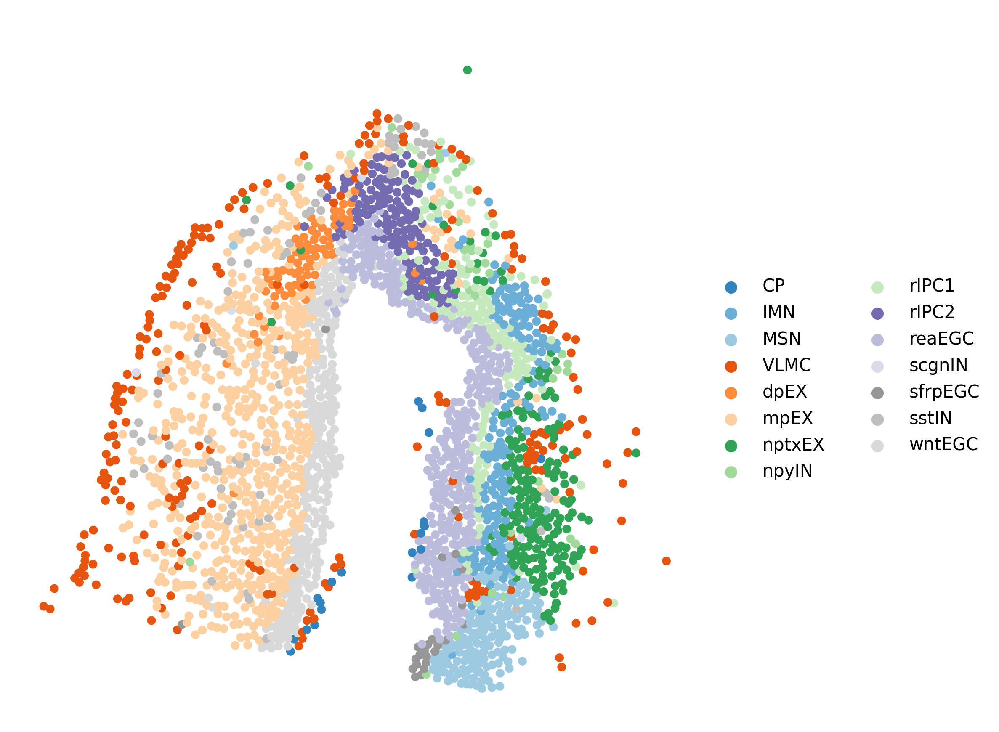

In [ ]:
fig, axs = plt.subplots(figsize=(7, 7))
# [创建绘图对象] 创建一个 Matplotlib 图形 (fig) 和一个子图 (axs)，设定图表大小为 7x7 英寸
ax = sc.pl.embedding(
    adata, 
    basis='X_spatial', 
    # [坐标基础] 关键参数：指定使用 AnnData.obsm['X_spatial'] 中存储的空间坐标作为绘图的 x 和 y 轴
    show=False,
    # [显示设置] 设置为 False，防止函数自动调用 plt.show()，以便手动保存图像
    color='cluster', 
    # [着色标签] 指定使用 AnnData.obs['cluster'] 列中存储的聚类标签来对 Spot 进行着色 
    ax=axs, 
    # [目标轴] 将绘图输出到之前创建的 Matplotlib 子图对象 axs 上 
    frameon=False, 
    # [边框] 设置为 False，移除图表的边框 
    title=' ', 
    # [标题] 设置图表标题为空
    palette='tab20c', 
    # [调色板] 指定使用 'tab20c' 调色板为不同的聚类着色
    size=100
    # [Spot 大小] 设置在空间图上绘制的每个 Spot 的大小为 100
)
# 作用：生成一张空间散点图，图中的 Spot 按照 'cluster' 标签着色，直观展示聚类结果在原始组织空间上的分布情况

**细胞类型/状态注释列表**

| 缩写标签 | 中文名称 | 英文全称/描述 |
| :--- | :--- | :--- |
| **ReEGC** | 反应性肠壁细胞 | Reactive Enteric Glial Cell |
| **rIPC** | 再生中间祖细胞 | Regenerating Intermediate Progenitor Cell |
| **INN** | 未成熟神经元 | Immature Neuron |
| **nptxEX** | Nptx + 外侧丘脑兴奋神经元 | Nptx + Excitatory Neuron (Lateral Thalamus) |
| **MSN** | 中刺神经元 | Medium Spiny Neuron |
| **sfrpEGC** | sfrp + 肠壁细胞 | sfrp + Enteric Glial Cell |
| **CP** | 脉络丛 | Choroid Plexus |
| **VLMC** | 血管轻脑膜细胞 | Vascular Leptomeningeal Cell |
| **wntEGC** | Wnt+ 肠壁细胞 | Wnt+ EGC |
| **mpEX** | 内侧丘脑兴奋神经元 | Medial Thalamus Excitatory Neuron |
| **sstIN** | Sst + 抑制性神经元 | Sst + Inhibitory Neuron |
| **scgnIN** | Scgn + 抑制性神经元 | Scgn + Inhibitory Neuron |
| **dpEX** | 背侧丘脑兴奋神经元 | Dorsal Thalamus Excitatory Neuron |

### 1.2 选择起始点

在使用 $\text{SpaTrack}$ 进行细胞分化轨迹推断之前，**选择起始簇**或指定一组细胞作为轨迹的起点是至关重要的一步，它直接影响所推断轨迹的可靠性和生物学意义。

### （1）起始簇选择方法

$\text{SpaTrack}$ 提供了多种方法来确定起始簇。我们建议用户**手动选择起始簇**，以确保轨迹的起点具有明确的生物学意义：

| 方法 | 描述 | 推荐度 |
| :--- | :--- | :--- |
| **手动选择** | 基于**先验知识和生物学证据**，手动指定起始细胞簇。 | **强烈推荐** |
| **自动选择** | 程序自动识别可能作为起点的细胞簇（例如基于熵值）。 | 备选方案 |

### （2）手动选择的策略

手动选择起始簇时，可依据以下策略：

* **熵值 ($\text{Entropy}$) 判据**：选择**熵值较高**的细胞簇，这通常表明该状态具有较高的**转录组异质性**或**多潜能性**。
* **空间坐标指定**：通过明确指定**空间坐标**来定位起始点。
* **套索 ($\text{Lasso}$) 工具**：使用可视化工具圈选感兴趣的细胞群作为起点。

### （3）本次分析的起始簇选择示例

以我们分析的钝口螈脑再生数据为例，我们根据生物学先验知识手动选择了 $\text{reaEGC}$（**反应性肠壁细胞**）作为起始细胞：

* **选择原因**：$\text{reaEGC}$ 细胞通常**覆盖损伤部位**，且具有**较高的熵值**，符合细胞处于响应损伤的早期状态的特征。

### 1.3 自动确定起始簇

评估每个簇中的熵值以确定起始簇。熵值越大，随机变量的不确定性就越高，信息量也就越大。在 spaTrack 中，熵值越高表示更有可能是起始簇。`stp.assess_start_cluster ()` 函数输出每个簇的熵值。`stp.assess_start_cluser_plot ()` 函数显示每个簇的排序熵值的盒图

对于这个数据，readEGC 具有最高的熵值，因此它更有可能是起始簇。

In [11]:
adata=spt.assess_start_cluster(adata)

AttributeError: module 'spaTrack' has no attribute 'assess_start_cluster'

建议用户根据先验知识和生物学证据手动选择起始簇。在没有这种知识的情况下，用户可以参考上述结果，这是自动确定的起始簇

### 1.4 手动选择spot(细胞)

In [13]:
start_cells = spt.set_start_cells(
    adata, 
    select_way='coordinates', 
    # [选择模式] 关键参数：基于空间坐标来确定起始点。
    cell_type='reaEGC', 
    # [目标聚类] 指定起始点必须在 'cluster' 列中属于 'reaEGC' 细胞类型
    start_point=[-1050,3850], 
    # [指定中心点] 提供一个精确的 (x, y) 坐标，作为搜索起始细胞的中心点
    n_neigh=30
    # [邻居数] 指定在中心点周围，要选取的最近的 30 个 Spot 作为起始细胞
)
# 作用：函数会找到最接近给定 start_point 的 Spot，并从属于 'reaEGC' 聚类中，选取其邻域的 30 个 Spot 作为最终的起始细胞集合。
# 结果：start_cells 是一个包含这些起始细胞**索引**的列表或数组

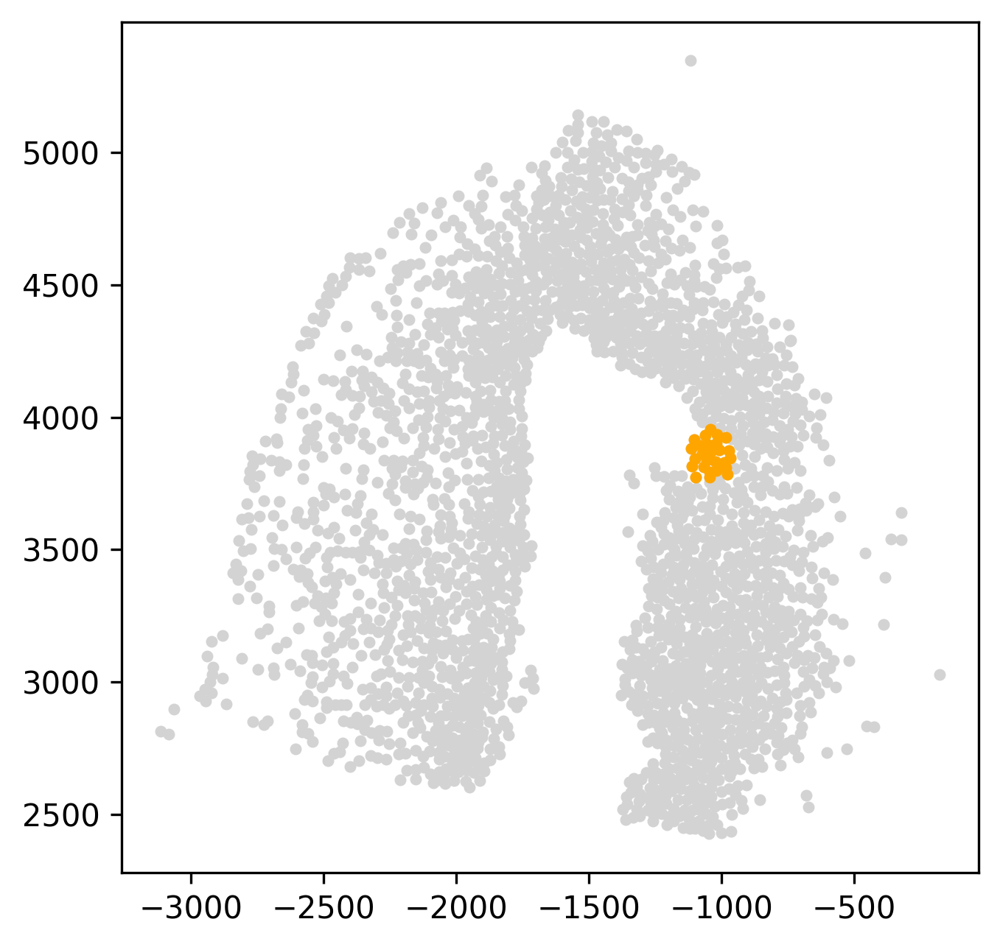

In [14]:
fig, axs = plt.subplots(figsize=(5,5))
# [创建绘图对象] 创建一个 5x5 英寸的 Matplotlib 图形和坐标轴
plt.scatter(
    adata.obsm['X_spatial'][:,0], 
    adata.obsm['X_spatial'][:,1], 
    c='#D3D3D3', 
    # [底色] 设置所有 Spot 的颜色为灰色 (#D3D3D3)
    s=8
    # [大小] 设置 Spot 的大小为 8
)
# 作用：绘制所有 Spot 的空间位置，作为背景
plt.scatter(
    adata.obsm['X_spatial'][start_cells][:,0], 
    # [X 坐标] 仅使用 start_cells 索引筛选后的 Spot 的 X 坐标。
    adata.obsm['X_spatial'][start_cells][:,1], 
    # [Y 坐标] 仅使用 start_cells 索引筛选后的 Spot 的 Y 坐标。
    c='orange', 
    # [突出颜色] 设置起始细胞的颜色为醒目的橙色 (orange)。
    s=8
)
# 作用：在背景图上叠加绘制选定的起始细胞，用橙色突出显示，以直观确认它们是否位于预期的空间位置（例如损伤区域）

#### 按细胞类型选择起始细胞

In [ ]:
# start_cells=spt.set_start_cells(adata,select_way='cell_type',cell_type='reaEGC')

# fig, axs = plt.subplots(figsize=(5,5))
# plt.scatter(adata.obsm['X_spatial'][:,0],adata.obsm['X_spatial'][:,1],c='#D3D3D3',s=8)
# plt.scatter(adata.obsm['X_spatial'][start_cells][:,0],adata.obsm['X_spatial'][start_cells][:,1],c='orange',s=8)

#### 手动选取细胞

In [17]:
# L=spt.Lasso(adata)
# L.vi_plot(basis='spatial',cell_type='reaEGC')

    'data': [{'marker': {'color': array(['#1f77b4', '#1f77b4', '#1f77b4', ..., '…

In [ ]:
# start_cells=L.sub_cells
# fig, axs = plt.subplots(figsize=(5, 5))
# plt.scatter(adata.obsm['X_spatial'][:,0],adata.obsm['X_spatial'][:,1],c='#D3D3D3',s=8)
# plt.scatter(adata.obsm['X_spatial'][start_cells][:,0],adata.obsm['X_spatial'][start_cells][:,1],c='orange',s=8)

### 1.5 计算细胞转移概率

**SpaTrack 轨迹速度计算与 OT 矩阵**

为了从空间转录组（$\text{ST}$）数据中计算细胞状态的**轨迹速度**（$\text{Trajectory Velocity}$），$\text{SpaTrack}$ 需要首先计算一个 **细胞转换概率矩阵** ($\text{T}$)，该步骤通过**最优传输 ($\text{Optimal Transport, OT}$) 理论**实现。

**1. 输入矩阵与计算目标**

| 输入矩阵 | 维度 ($\text{N}$ = Spot/细胞数, $\text{M}$ = 基因数) |
| :--- | :--- |
| **基因表达矩阵** | $\text{N} \times \text{M}$ |
| **转换概率矩阵** ($\text{T}$) | $\text{N} \times \text{N}$ |

**2. 核心原理与空间整合**

* **原理**：$\text{OT}$ 理论计算最小化转换成本的“传输计划” $\text{T}$。
* **成本函数**：转换成本结合了**基因表达差异**和**空间距离**。
* **空间整合**：在 $\text{spt.get\_ot\_matrix()}$ 中，我们将数据类型设置为 **`'spatial'`**，以确保**细胞的空间位置信息**被整合到转换成本的计算中，从而获得更准确的转换概率。

**3. 权重 ($\alpha$) 参数设置**

| 参数 | 默认值 | 意义 |
| :--- | :--- | :--- |
| **$\alpha_1$ 和 $\alpha_2$** | $0.5$ 和 $0.5$ | 分别代表基因表达差异和空间距离的**权重**。默认值 $0.5$ 假设两者独立且同等重要。 |

* **当前优化**：为了确定最佳权重，我们当前使用 $\text{R}$ 中的 **`r-spdep`** 包来计算 $\alpha$ 的最优值。

In [18]:
adata.obsp["trans"] = spt.get_ot_matrix(adata, data_type="spatial",alpha1=0.6,alpha2=0.4)

X_pca is not in adata.obsm, automatically do PCA first.


### 1.6 计算细胞拟时序

在计算出细胞间的**转换概率矩阵** ($\text{T}$) 之后，为了确定每个细胞在推断轨迹上的相对位置，需要进行拟时间赋值。

1. 计算初始单元的转移概率之和

* **操作**：计算所有**初始单元**（$\text{Start Cells}$/根节点）转移到**数据集中每个单元格**的**概率之和**。
* **结果**：根据此转移概率之和对所有单元格进行排序。

2. 拟时间 ($\text{Ptime}$) 赋值

最终的拟时间 ($\text{Ptime}$) 值被标准化分配在 $[0, 1]$ 之间，采用**算术序列**（线性插值）进行赋值：

| 转移概率之和 | 拟时间 ($\text{Ptime}$) 值 | 意义 |
| :--- | :--- | :--- |
| **最大** | $0$ | 这些单元格**最容易**从起始细胞转移而来，代表轨迹上的**最早期状态**。 |
| **最小** | $1$ | 这些单元格**最难**从起始细胞转移而来，代表轨迹上的**最晚期状态**（或终点）。 |

**总结**：拟时间值量化了每个细胞与起始状态的“距离”，将空间和转录组的演变路径转化为一个连续的、有方向性的时间轴

In [19]:
adata.obs["ptime"] = spt.get_ptime(adata, start_cells)

轨迹速度 ($\text{Velocity}$) 的计算与可视化

在为每个细胞分配了拟时间 ($\text{Ptime}$) 值后，下一步是计算细胞状态在空间中的演变速度和方向。

1. 确定细胞邻居 ($\text{Cell Neighbors}$)

细胞邻居集是计算速度向量的基础：

* **空间数据 ($\text{ST}$)**：基于空间坐标 **$\text{'X\_spatial'}$** 确定邻居（参数 $\text{'n\_neigh\_pos'}$）。
* **单细胞数据 ($\text{scRNA}$)**：基于嵌入坐标 **$\text{'UMAP'}$** 确定邻居。
* **最终邻居集**：采用空间坐标邻居和嵌入矩阵邻居的**交集**，以提高准确性。

2. 计算细胞速度向量

细胞的速度向量由方向和大小决定：

确定速度方向 ($\text{Direction}$)

1.  **初始方向**：从当前细胞指向其邻居的方向。
2.  **拟时间校正**：
    * 如果**邻居的 $\text{Ptime}$ 值**大于当前细胞，方向保持不变（从早期到晚期）。
    * 如果**邻居的 $\text{Ptime}$ 值**小于当前细胞，则**反转速度方向**。

确定速度大小（连接速度 $\text{Conjunctive Speed}$）

* **连接速度**：使用该细胞到其邻居的**细胞转换概率**作为速度大小。
* **最终速度**：该细胞的最终轨迹速度是其到所有邻居的**平均连接速度值**。

网格速度计算与流线图可视化

为了绘制平滑的速度流线图 ($\text{Streamline Plot}$)，需要将离散的细胞速度转换为网格速度：

1.  **网格划分**：将二维平面划分为 $50 \times 50$ 的网格。
2.  **网格速度赋值**：以网格点附近邻近细胞的平均速度作为该网格点的速度。
3.  **权重分配**：**细胞与网格点的距离**决定了其速度对网格点速度的贡献**权重**（越近权重越大）。

In [20]:
adata.uns["E_grid"], adata.uns["V_grid"] = spt.get_velocity(adata, basis="spatial", n_neigh_pos=50)

The velocity of cells store in 'velocity_spatial'.


### 1.7 可视化结果

这里，起始细胞信息、细胞拟时间值和细胞速度结果都已存储在 `adata` 对象中。用户现在可以从 `adata` 中可视化这些焦点信息。接下来，我们将展示拟时间值分布图、细胞颤抖图（quiver plot）和细胞轨迹图。

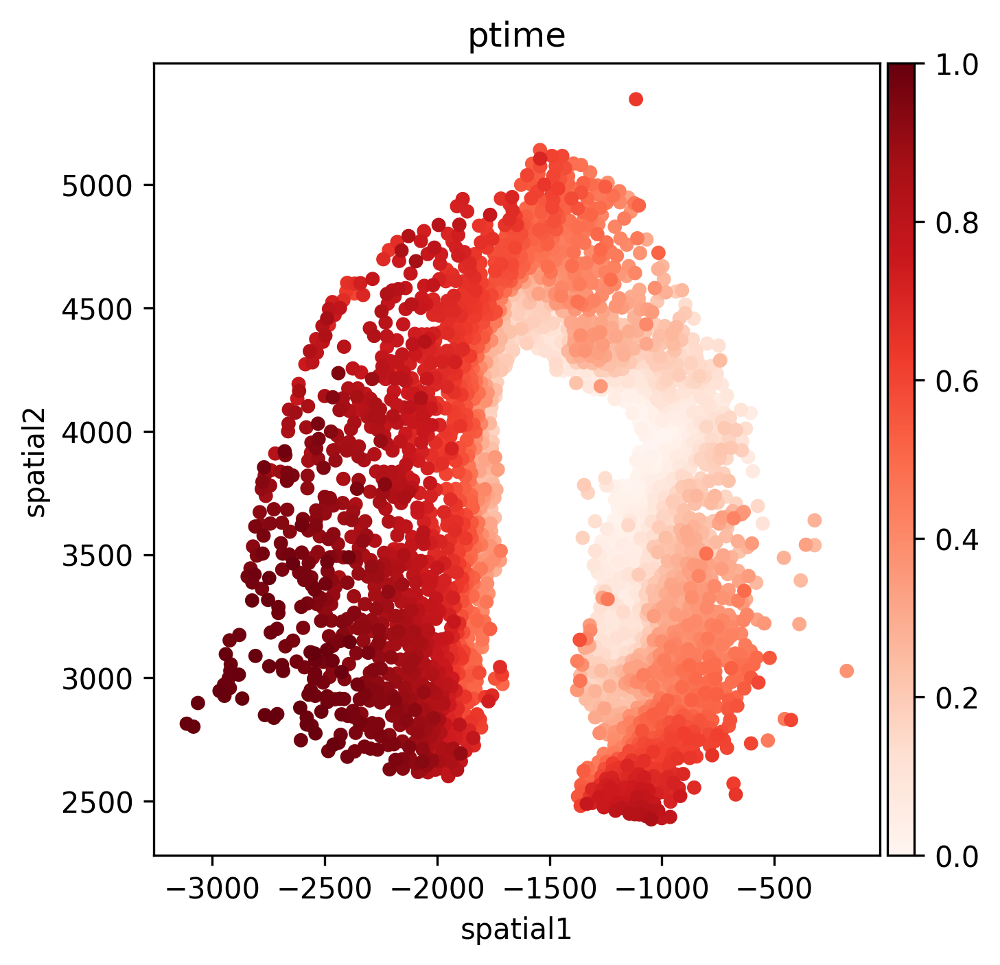

In [ ]:
fig, axs = plt.subplots(figsize=(5, 5))
# [创建绘图对象] 创建一个 Matplotlib 图形 (fig) 和一个子图 (axs)，设定图表大小为 5x5 英寸。

sc.pl.embedding(
    adata, 
    basis='spatial', 
    # [坐标基础] 指定使用 AnnData.obsm['spatial'] 中的空间坐标作为绘图轴（注意：虽然您之前设置为 'X_spatial'，但 Scanpy 可能会将其映射到 'spatial' 或您需要确认实际键名）
    color='ptime', 
    # [着色标签] **关键参数**：指定使用 AnnData.obs['ptime'] 中存储的拟时间值来对 Spot 进行着色
    show=False, 
    ax=axs, 
    # [目标轴] 将绘图输出到之前创建的 Matplotlib 子图对象 axs 上
    color_map='Reds', 
    # [颜色映射] 使用 'Reds' 颜色方案。通常，颜色越深（越红），表示拟时间值越大，即越接近轨迹的终点
    title='ptime', 
    # [标题] 设置图表标题为 'ptime'
    size=100
    # [Spot 大小] 设置在空间图上绘制的每个 Spot 的大小
)
# 作用：生成一张空间散点图，用颜色梯度展示细胞状态从轨迹起点（颜色浅）到轨迹终点（颜色深）的空间演变模式

axs.xaxis.set_major_locator(ticker.MultipleLocator(500))
# [X轴刻度] 设置 X 轴的主要刻度间隔为 500 个单位
# 目的：确保空间坐标轴的刻度间隔清晰、易读

axs.yaxis.set_major_locator(ticker.MultipleLocator(500))
# [Y轴刻度] 设置 Y 轴的主要刻度间隔为 500 个单位。

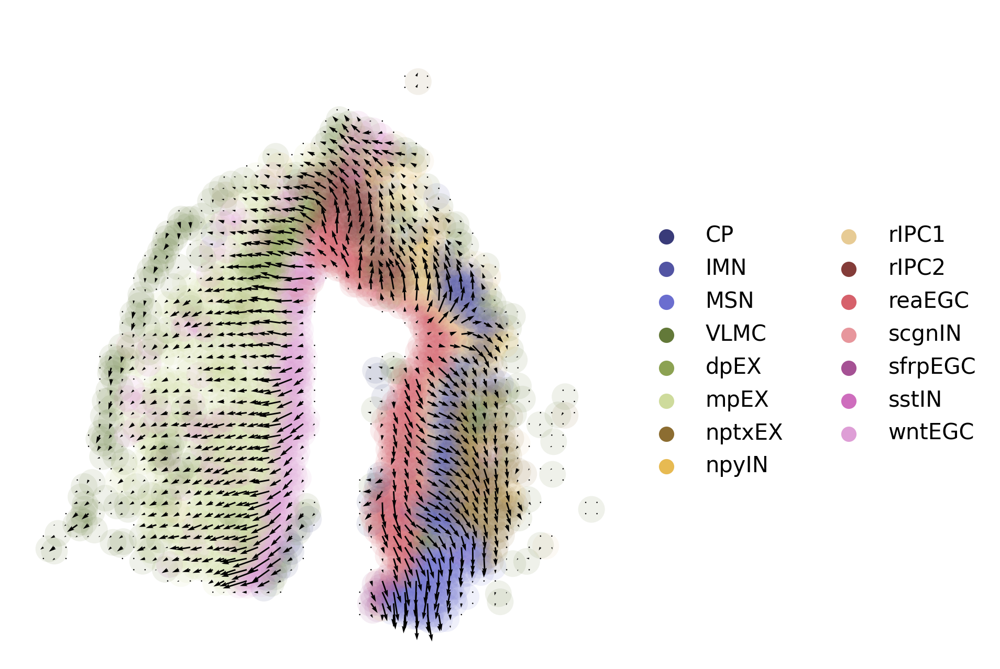

In [22]:
sc.pl.embedding(
    adata, 
    basis='spatial', 
    show=False,
    title=' ',
    color='cluster', 
    # [着色标签] 按照 'cluster' 标签对 Spot 进行着色
    ax=axs,
    frameon=False,
    palette='tab20b',
    legend_fontweight='normal',
    alpha=0.1, 
    # [透明度] 设置 Spot 的透明度为 0.1。目的：让背景 Spot 保持非常浅淡，不干扰前景的速度向量
    size=600 
    # [Spot 大小] 设置 Spot 的大小为 600
)
# 作用：在图上绘制一个非常大且透明的 Spot 散点图，用聚类信息着色，作为速度场的参照背景

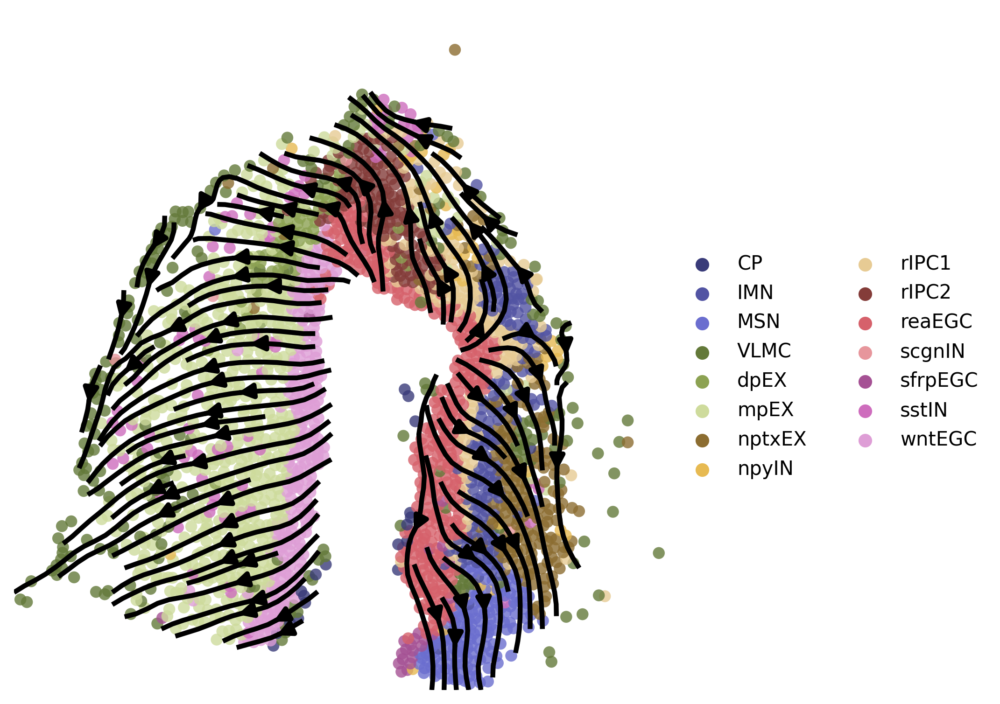

In [23]:
ax = sc.pl.embedding(
    adata, 
    basis='spatial', 
    show=False,
    title=' ',
    color='cluster', 
    # [着色标签] 按照 'cluster' 标签对 Spot 进行着色。
    ax=axs,
    frameon=False,
    palette='tab20b',
    legend_fontweight='normal',
    alpha=0.8, 
    # [透明度] Spot 透明度为 0.8，保证聚类背景清晰可见
    size=150 
    # [Spot 大小] Spot 大小设置为 150
)
# 作用：提供一个清晰的组织空间背景，展示细胞聚类在空间中的实际分布
ax.streamplot(
    adata.uns['E_grid'][0],  # X 坐标网格点
    adata.uns['E_grid'][1],  # Y 坐标网格点
    adata.uns['V_grid'][0],  # X 坐标的速度分量 (u)
    adata.uns['V_grid'][1],  # Y 坐标的速度分量 (v)
    density=1.8,  
    # [密度] **关键参数**：控制流线的疏密程度。密度 1.8 意味着流线会相对密集
    color='black',  
    # [颜色] 设置流线的颜色为黑色，使其在背景色上突出
    linewidth=2.5,  
    # [线宽] 设置流线的宽度为 2.5，使其轨迹清晰可见
    arrowsize=1.5 
    # [箭头大小] 设置流线上箭头的相对大小为 1.5，用于指示轨迹的精确方向。
)
# 作用：基于网格化的速度向量（V_grid）生成连续、平滑的流线
# 目的：清晰地展示细胞状态在整个组织空间中，从起始簇（如 reaEGC）流向各个终末状态的主导轨迹和演变路径

### 1.8 下游分析

**最少作用路径 ($\text{Least Action Path, LAP}$) 算法在轨迹分支分析中的应用**

在推断出细胞分化轨迹后，我们关注经历**分支**的细胞类型群。轨迹分支通常代表**细胞命运决定的关键时刻**，对理解脑再生等复杂生物学过程至关重要。

**算法核心原理**

$\text{LAP}$ 算法（源于物理学中的最小作用量原理）用于识别细胞状态转变的**最优路径**。

* **作用**：识别细胞从一个状态过渡到另一个状态时，**概率最高、所需“能量”（或作用量）最小**的路径。
* **最小化能量**：这里的“能量”代表细胞状态转变所需的**转录组变化或障碍**。$\text{LAP}$ 旨在最小化克服这些障碍所需的**总体成本**。

**LAP的应用目标**

通过对轨迹分支应用 $\text{LAP}$ 算法，我们可以：

* **预测最优转变路径**：确定细胞如何沿着**最少阻力**的路径，从一个共同的祖细胞状态演变为特定的子细胞类型。
* **识别关键驱动基因**：沿着这条**最少作用路径**，细胞的基因表达变化是最剧烈和最关键的。这有助于识别驱动细胞命运**转变和分化**的**关键驱动基因** ($\text{Key Driver Genes}$)。

**总结**：$\text{LAP}$ 算法为量化细胞命运转变提供了工具，揭示了在细胞状态转换过程中，哪些分子事件是决定性的。

### 1.9 最小行动路径 (LAP) 段

为了在空间转录组数据上准确地应用最少作用路径 (LAP) 算法来预测细胞命运转变的最优路线，我们需要一个非常精细的速度信息。通常，我们计算的速度向量是平滑化到网格上的，但 LAP 需要每个细胞自身的精确速度。因此，我们对算法进行了优化：我们将网格上的速度场重建回细胞点级别。这样做的好处是，LAP 可以依据每个细胞的准确速度来推断出最符合细胞状态演变意图的路径，从而排除那些与轨迹关联较弱的细胞的干扰，最终找到最可靠的细胞命运转变主路径

In [ ]:
VecFld = spt.VectorField(
    adata, 
    # [AnnData 对象] 输入数据对象，必须已经包含
    # 1. 拟时间 (adata.obs['ptime']) 结果。
    # 2. 细胞邻居信息（可能存储在 adata.uns 或 adata.obsp 中）。
    # 3. 细胞转换概率矩阵（adata.obsp['trans']）。
    basis='spatial'
    # [坐标基础] **关键参数**：指定用于计算和表示速度场的坐标系统
    # - 'spatial'：指示使用 AnnData.obsm['X_spatial'] 中存储的空间坐标来构建速度场
)
# 作用：
# 1. 初始化一个 VectorField 对象 (VecFld)
# 2. 核心功能：执行细胞速度（Velocity）的计算，包括确定细胞邻居、计算速度方向和大小（连接速度），并将网格级速度场重建为细胞级（如您之前所述）
# 3. 结果存储：计算出的速度信息，包括细胞速度和网格速度，通常会存储在 adata.uns 或 VecFld 对象的内部属性中
# 目的：为后续的 LAP (Least Action Path) 算法提供必需的细胞状态演变方向和速率信息

要推断细胞状态转变的最少作用路径 (LAP)，首先需要明确指定起始细胞和结束细胞。LAP 算法会利用每个细胞的速度信息，在整个速度场中搜索从起点到终点的最佳路径。它的核心原理是最小化作用量积分，该积分衡量了沿着路径转变所需的总动能或总阻力。因此，LAP 找到的路径代表了在当前细胞状态演变趋势下，两个指定细胞状态之间最可能、最经济的过渡路线。

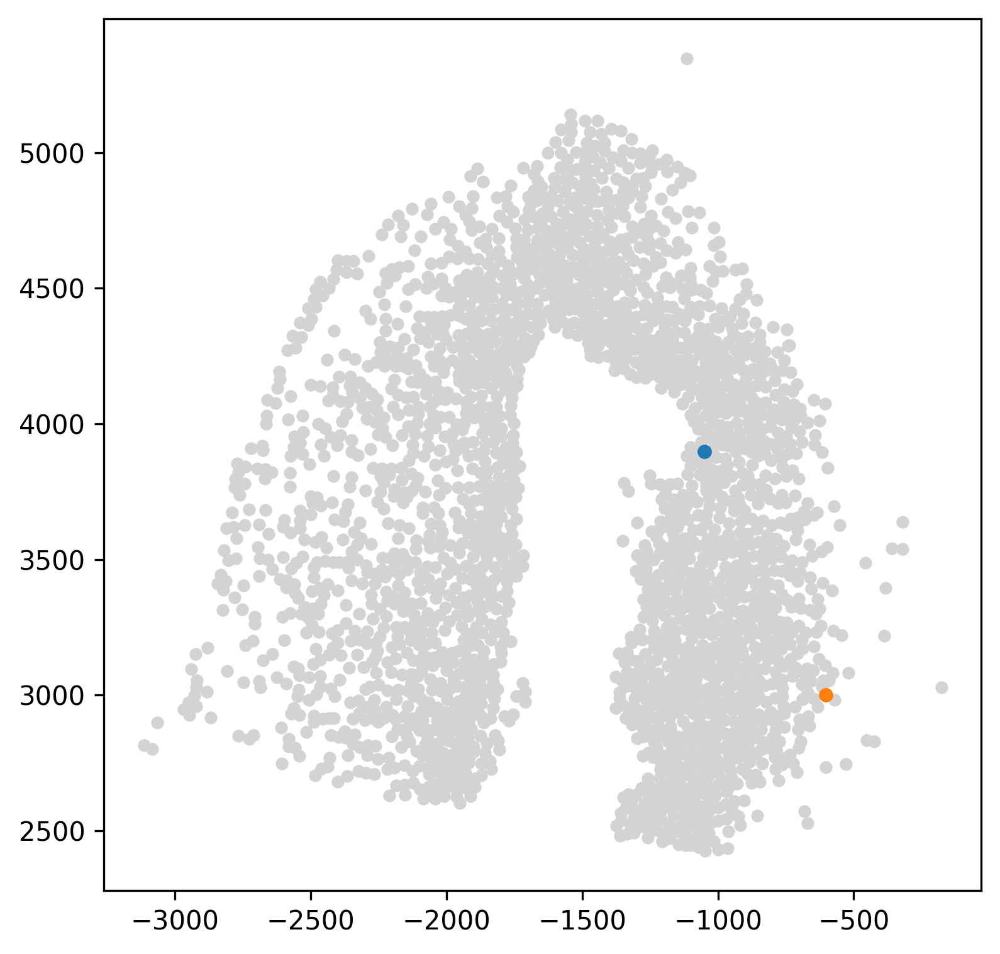

In [25]:
fig, ax = plt.subplots(figsize=(6, 6))
# [创建绘图对象] 创建一个 6x6 英寸的 Matplotlib 图形和坐标轴
LAP_start_point=[-1050,3900]
# [起始坐标] 定义用户指定的轨迹起始点的 (X, Y) 空间坐标
LAP_end_point=[-625,3000]
# [结束坐标] 定义用户指定的轨迹终点的 (X, Y) 空间坐标
LAP_start_cell=spt.nearest_neighbors(LAP_start_point,adata.obsm['X_spatial'])[0][0]
# [确定起始细胞] 使用 spt.nearest_neighbors 找到最接近 LAP_start_point 坐标的 Spot 的索引
# - 目的：将抽象的坐标点映射到 AnnData 对象中的实际细胞/Spot
LAP_end_cell=spt.nearest_neighbors(LAP_end_point,adata.obsm['X_spatial'])[0][0]
# [确定结束细胞] 找到最接近 LAP_end_point 坐标的 Spot 的索引
# - 目的：确定 LAP 轨迹的终点细胞

plt.scatter(*adata.obsm["X_spatial"].T,c='#D3D3D3',s=15)
# [绘制背景] 绘制所有 Spot 的空间位置，颜色为灰色 (#D3D3D3)，Spot 大小为 15，作为背景

plt.scatter(*adata[LAP_start_cell].obsm['X_spatial'].T,s=20)
# [突出起始细胞] 在背景图上，单独绘制并突出显示选定的起始细胞
# - 默认使用 Matplotlib 的下一个颜色（通常是蓝色或橙色），且点的大小 (s=20) 略大，以便识别

plt.scatter(*adata[LAP_end_cell].obsm['X_spatial'].T,s=20)
# [突出结束细胞] 在背景图上，单独绘制并突出显示选定的结束细胞
# - 使用 Matplotlib 的再下一个颜色，且点的大小 (s=20) 略大
# 作用：直观地确认用户定义的 LAP 起点和终点是否被正确地映射到组织空间中的目标细胞上

最少作用路径 (LAP) 算法是一种基于细胞速度来确定特定起始点和终点之间最优转变路线的方法。它通过采用期望最大化 (EM) 算法来搜索具有最低作用量（即最小总阻力）的路径，并通过迭代更新直到收敛。用户还可以通过调整算法的步数，来确保获得的 LAP 路径更加平滑和最优

In [ ]:
lap = spt.least_action(
    adata,
    init_cells=adata.obs_names[LAP_start_cell],
    # [起始细胞]：指定轨迹的起始细胞。这里通过索引 (LAP_start_cell) 找到对应的细胞名称
    target_cells=adata.obs_names[LAP_end_cell],
    # [结束细胞]：指定轨迹的终点细胞。通过索引 (LAP_end_cell) 找到对应的细胞名称。
    vecfld=VecFld,
    # [速度场对象]：传入之前计算和初始化的 VecFld 对象，其中包含细胞级别的速度向量信息
    basis='spatial',
    # [坐标基础] 指定 LAP 搜索和定义的空间维度基础，确保路径是在空间坐标上进行评估的
    adj_key='X_spatial_distances',
    # [邻接矩阵键] 指定存储细胞间距离信息的键
    EM_steps=5,
    # [EM 迭代步数] ：设置期望最大化 (EM) 算法的迭代次数为 5。这决定了 LAP 路径的优化程度和计算时间
    n_points=20
    # [路径点数]：设置最终 LAP 路径由 20 个等间距的点组成。这决定了输出路径的平滑度和解析度
)
# 作用：执行迭代优化过程，找到使作用量积分最小化的、从 init_cells 到 target_cells 的最优过渡路径
# 结果：lap 变量存储了计算出的最少作用路径的坐标、作用量等信息，通常是一个 DataFrame 或类似的结构

在利用最少作用路径 (LAP) 算法确定了最优过渡路径后，我们会根据细胞在 LAP 上的位置为其重新分配一个新的拟时间 (Pseudotime) 值。随后，我们将这条 LAP 路径绘制出来进行可视化，这不仅能直观展示细胞命运转变的最优进程，还能为我们沿着这条精确的轨迹分析潜在的关键驱动基因提供数据基础

In [27]:
LAP_ptime, LAP_nbrs = spt.map_cell_to_LAP(adata, cell_neighbors=80)
# [映射细胞到 LAP] 使用 spt.map_cell_to_LAP 函数：
# - 作用：将 LAP 路径周围的细胞映射到这条最优路径上
# - cell_neighbors=80：指定在 LAP 路径周围，选择最近的 80 个细胞作为聚焦的细胞群。
# - 结果：LAP_ptime 存储了这些细胞基于 LAP 的新拟时间值；LAP_nbrs 存储了这些被选中细胞的索引

sub_adata = adata[LAP_nbrs, :]
# [创建子集] 从原始 AnnData 对象 (adata) 中，提取出被选中的 80 个细胞，创建新的子集 AnnData 对象 (sub_adata)

sub_adata.obs['ptime'] = LAP_ptime
# [赋值新拟时间] 将基于 LAP 映射计算出的新拟时间值 (LAP_ptime) 赋值给子集对象的 sub_adata.obs['ptime'] 槽位

sub_adata = sub_adata[np.argsort(sub_adata.obs["ptime"].values), :].copy()
# [按拟时间排序] 根据新的 'ptime' 值对 sub_adata 中的细胞进行排序（从小到大）
# 目的：确保细胞按轨迹的正确顺序排列，方便后续分析和可视化

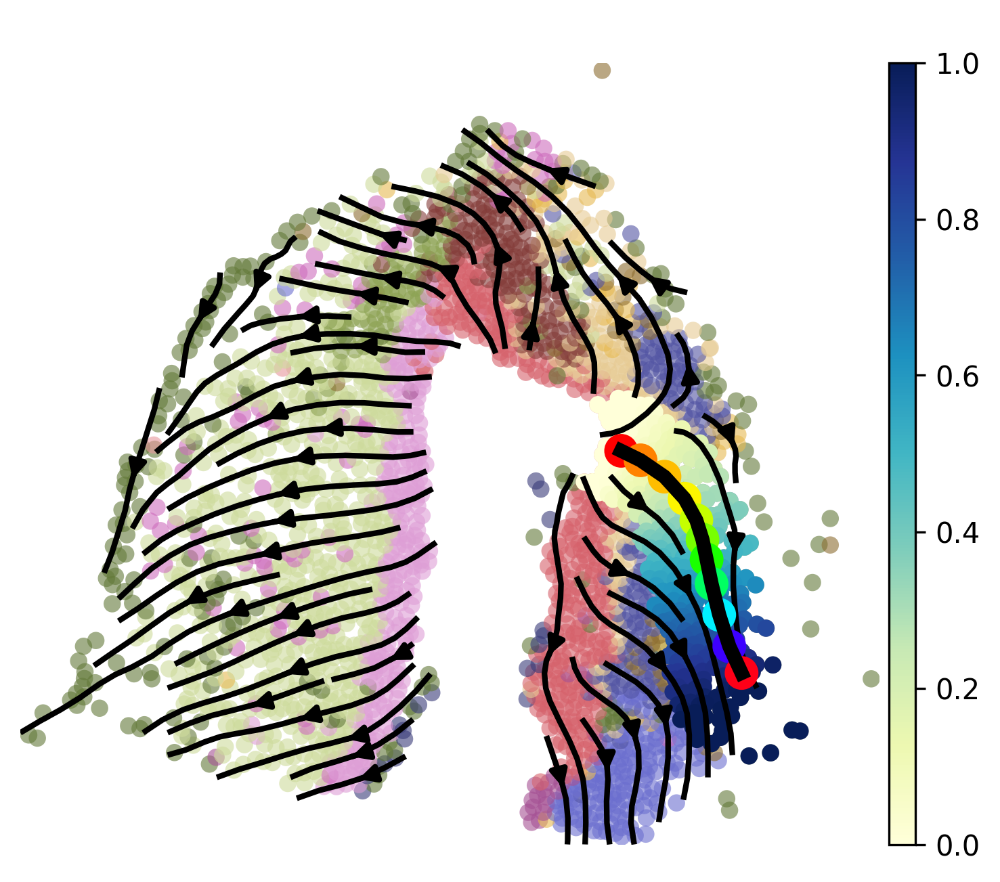

In [28]:
fig, ax = plt.subplots(figsize=(6, 5))
plt.axis('off')
# [初始化绘图] 创建一个 6x5 的图表并关闭坐标轴，以获得纯净的组织图
ax = sc.pl.embedding(
    adata, basis='X_spatial', color='cluster', show=False, ax=ax,
    frameon=False, legend_loc=None, alpha=0.6, size=150
)
# [绘制背景聚类] 绘制所有细胞的聚类图，作为速度流线的空间背景
ax.streamplot(
    adata.uns['E_grid'][0], adata.uns['E_grid'][1], 
    adata.uns['V_grid'][0], adata.uns['V_grid'][1],
    density=1.2, color='black', linewidth=2, arrowsize=1.2
)
# [绘制速度流线] 在背景图上叠加绘制平滑的细胞速度流线图，展示整体的细胞状态演变趋势

ax = spt.plot_least_action_path(adata, basis='spatial', ax=ax, point_size=120, linewidth=5)
# [绘制 LAP 轨迹线] **关键步骤**：在图上叠加绘制之前计算出的 LAP 轨迹线
# - point_size=120, linewidth=5：设置 LAP 轨迹线的点和线宽，使其比流线更粗更突出

sc.pl.embedding(
    sub_adata, basis='X_spatial', ax=ax, color="ptime", cmap="YlGnBu",
    frameon=True, size=150, title=' '
)
# [可视化 LAP 细胞的 Ptime] 
# - 输入：使用 sub_adata（仅包含 LAP 路径周围的细胞）
# - 着色：根据新赋值的 'ptime' 值着色
# - 颜色映射：使用 'YlGnBu'（黄绿蓝）颜色图，清晰展示细胞沿着 LAP 轨迹从起始（黄）到结束（蓝）的状态渐变
# 作用：最终图表清晰地展示了整体速度场、最优 LAP 路径，以及路径上细胞随拟时间演变的精确过程

### 1.10 LAP 上的伪时间依赖性基因

为了鉴定驱动细胞转化沿最优转化路径的基因，我们使用广义相加模型 (GAM) 拟合基因表达值和细胞伪时间值。这使我们能够鉴定与伪时间值显著相关的基因，因此被认为是伪时间依赖性基因

首先，我们选择聚焦于最优转化途径的细胞类型，筛选变异性高且表达水平大于最小表达比例的基因

In [29]:
sub_adata_path = sub_adata[sub_adata.obs['cluster'].isin(['reaEGC', 'rIPC1', 'IMN', 'nptxEX'])]
# [细胞过滤] 从 sub_adata 中，仅选择 'cluster' 标签属于以下四种细胞类型的 Spot：
# - 'reaEGC' (反应性肠壁细胞，起始点附近)
# - 'rIPC1' (再生中间祖细胞)
# - 'IMN' (未成熟神经元)
# - 'nptxEX' (Nptx + 外侧丘脑兴奋神经元，终点附近)
# 作用：将分析范围缩小到 LAP 所连接的核心分化轴上的关键细胞状态，排除无关的旁支细胞

sub_adata_path = spt.filter_gene(sub_adata_path, min_exp_prop=0.1, hvg_gene=3000)
# [基因过滤] 使用 SpaTrack 的 spt.filter_gene 函数对聚焦的细胞子集 (sub_adata_path) 进行基因筛选
# - min_exp_prop=0.1：要求基因至少在 10% 的细胞中表达，以过滤掉极度稀疏的基因
# - hvg_gene=3000：在满足表达比例要求的基因中，进一步选择表达变异性最高的 3000 个基因（高变基因，HVGs）
# 目的：确保后续的驱动基因分析集中在最可能驱动细胞状态转变的、具有显著表达差异的基因上，提高分析的效率和生物学解释力

clusters ordered by ptime:  ['reaEGC', 'rIPC1', 'IMN', 'nptxEX']
Cell number	261
Gene number	1093


然后，我们使用广义相加模型拟合基因表达和相应的细胞伪时间。

为了过滤伪时间依赖性基因，我们通过计算 R2 值来评估模型拟合的质量。我们还使用多次测试校正来控制错误发现率 (FDR)。R2 值高、FDR 低的基因被认为是伪时间依赖性基因，这可能对于驱动细胞命运沿最优转变路径的转变很重要

In [30]:
df_res = spt.ptime_gene_GAM(
    sub_adata_path,
    # [输入数据] 之前筛选出的、沿着 LAP 轨迹的细胞子集 (sub_adata_path)
    # - 关键：该子集已包含基于 LAP 位置重新赋值的拟时间 (sub_adata_path.obs['ptime'])
    core_number=5
    # [并行核心数] 指定用于并行计算的核心数为 5
    # 目的：加速 GAM 模型的拟合过程
)

Genes number fitted by GAM model:   1093


In [ ]:
df_sig_res = df_res.loc[(df_res['model_fit']>0.2) & (df_res['fdr']<0.05)]
# [筛选操作] 使用 Pandas 的 loc 方法对 df_res 数据框进行两步布尔索引筛选：
# 1. 生物学显著性过滤： (df_res['model_fit'] > 0.2)
# - 'model_fit'：衡量 GAM 模型拟合数据的优劣，通常是 R² 或类似指标。
# - 过滤标准：要求模型的拟合优度 (model_fit) 大于 0.2
# - 目的：确保选出的基因表达变化是可信且与 ptime 强相关的（即基因表达的动态变化至少有 20% 可以由 ptime 解释），排除拟合效果差的基因

# 2. 统计学显著性过滤： (df_res['fdr'] < 0.05)
# - 'fdr' (False Discovery Rate)：经过多重检验校正后的 p 值。
# - 过滤标准：要求关联的统计学显著性 FDR 小于 0.05
# - 目的：确保基因表达随 ptime 变化的关系在统计上是显著的，控制假阳性率

Finally selected 50 genes.


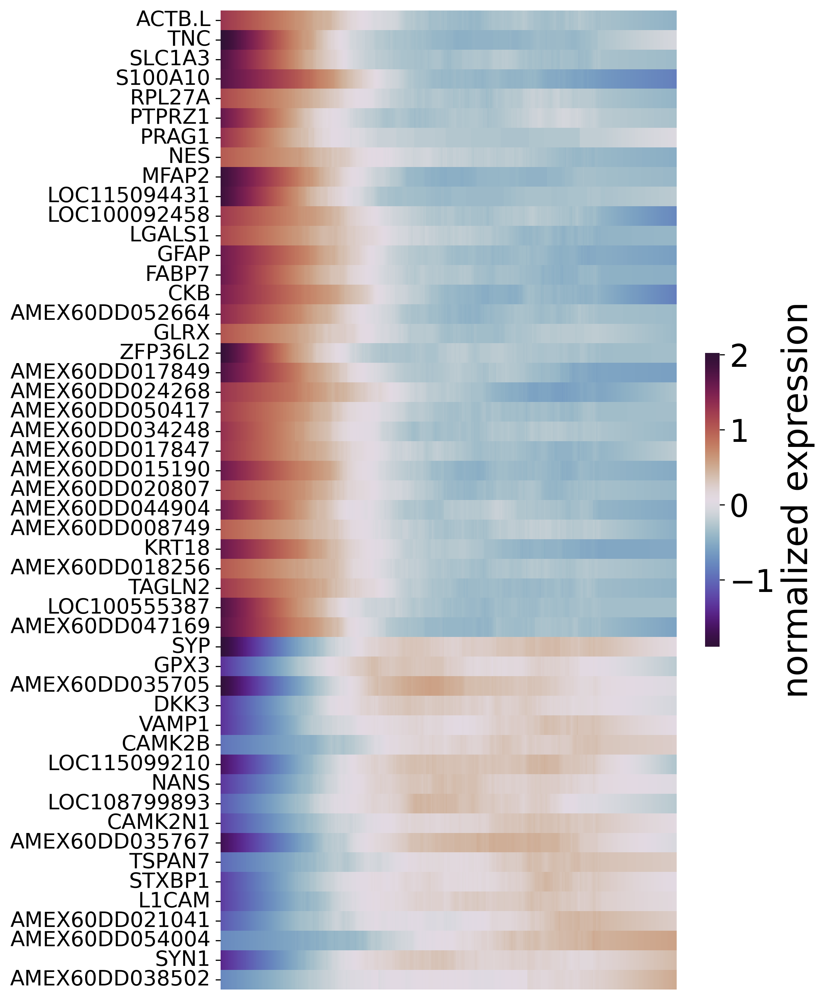

In [32]:
sort_exp_sig = spt.order_trajectory_genes(
    sub_adata,
    df_sig_res,
    # [输入基因列表] 之前筛选出的、统计和生物学显著的驱动基因列表 (df_sig_res)
    cell_number=20
    # [平滑采样点] 指定用于排序和可视化的细胞采样数量为 20
    # 目的：将 sub_adata 沿着 Ptime 轴分成 20 个“bin”或采样点，计算每个 bin 的平均基因表达，从而简化和平滑数据，以便更好地观察趋势
)
# 作用：基于基因表达随 Ptime 变化的模式，对 df_sig_res 中的显著基因进行重新排序。通常，排序依据是基因表达达到峰值的时间点
# 结果：sort_exp_sig 是一个包含排序后基因表达数据的矩阵或 DataFrame
spt.plot_trajectory_gene_heatmap(
    sort_exp_sig,
    smooth_length=100,
    # [平滑长度] 指定用于可视化目的的平滑程度或数据点数量。这进一步确保热图中的趋势是平滑连续的
    gene_label_size=15,
    # [基因标签大小] 设置热图 y 轴上基因名称标签的字体大小为 15
    cmap_name='twilight_shifted'
    # [颜色映射] 使用 'twilight_shifted' 颜色图。这是一种常用的双向或周期性颜色图，适合展示基因表达从低到高、或从早到晚的变化趋势
)
# 作用：生成一张热图。热图的 X 轴代表 LAP 拟时间（从 0 到 1），Y 轴是排序后的关键驱动基因。每个单元格的颜色表示该基因在对应 Ptime 阶段的表达水平
# 目的：直观地展示基因的表达级联 (expression cascade)：哪些基因在轨迹早期激活，哪些在晚期激活，从而揭示细胞命运转变的分子时序

# 环境信息

In [40]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/.local/share/mamba/envs/scvelo_env:
#
# Name                              Version          Build                               Channel
_libgcc_mutex                       0.1              conda_forge                         conda-forge
_openmp_mutex                       4.5              2_gnu                               conda-forge
adjusttext                          1.3.0            pyhd8ed1ab_0                        conda-forge
aiohappyeyeballs                    2.6.1            pyhd8ed1ab_0                        conda-forge
aiohttp                             3.12.15          py310h3406613_0                     conda-forge
aiosignal                           1.4.0            pyhd8ed1ab_0                        conda-forge
alsa-lib                            1.2.14           hb9d3cd8_0                          conda-forge
anndata                             0.10.5.post1     pypi_0                              pypi
anywidget             

CompletedProcess(args=['conda', 'list'], returncode=0)

In [41]:
subprocess.run(['pip', 'list'])

Package                   Version
------------------------- -----------------
adjustText                1.3.0
aiohappyeyeballs          2.6.1
aiohttp                   3.12.15
aiosignal                 1.4.0
anndata                   0.10.5.post1
anywidget                 0.9.18
array-api-compat          1.12.0
asciitree                 0.3.3
asttokens                 3.0.0
async-timeout             5.0.1
attrs                     25.3.0
bokeh                     3.8.0
branca                    0.8.1
Brotli                    1.1.0
cached-property           1.5.2
certifi                   2025.8.3
cffi                      1.17.1
charset-normalizer        3.4.3
click                     8.2.1
cloudpickle               3.1.1
colorama                  0.4.6
colorcet                  3.1.0
comm                      0.2.3
contourpy                 1.2.1
cosine-similarity         0.1.2
cycler                    0.12.1
cytoolz                   1.0.1
dask                      2024.11.2
dask-

CompletedProcess(args=['pip', 'list'], returncode=0)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 